In [61]:
import kagglehub

# Download latest version
path = kagglehub.competition_download("demand-forecasting-kernels-only")

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/demand-forecasting-kernels-only


In [62]:
from pathlib import Path
from statsmodels.tsa.seasonal import MSTL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit


pd.set_option('display.max_columns', None)

In [63]:
# Load data
train = pd.read_csv(Path(path) / "train.csv")
test = pd.read_csv(Path(path) / "test.csv")

print(train.shape, test.shape)

(913000, 4) (45000, 4)


In [64]:
train.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [65]:
test.head()

,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


In [66]:
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])

In [67]:
train_start = train.date.min().date()
train_end = train.date.max().date()
print('Train Start: ', train_start)
print('Train End: ', train_end)

Train Start:  2013-01-01
Train End:  2017-12-31


In [68]:
test_start = test.date.min().date()
test_end = test.date.max().date()
print('Test Start: ', test_start)
print('Test End: ', test_end)

Test Start:  2018-01-01
Test End:  2018-03-31


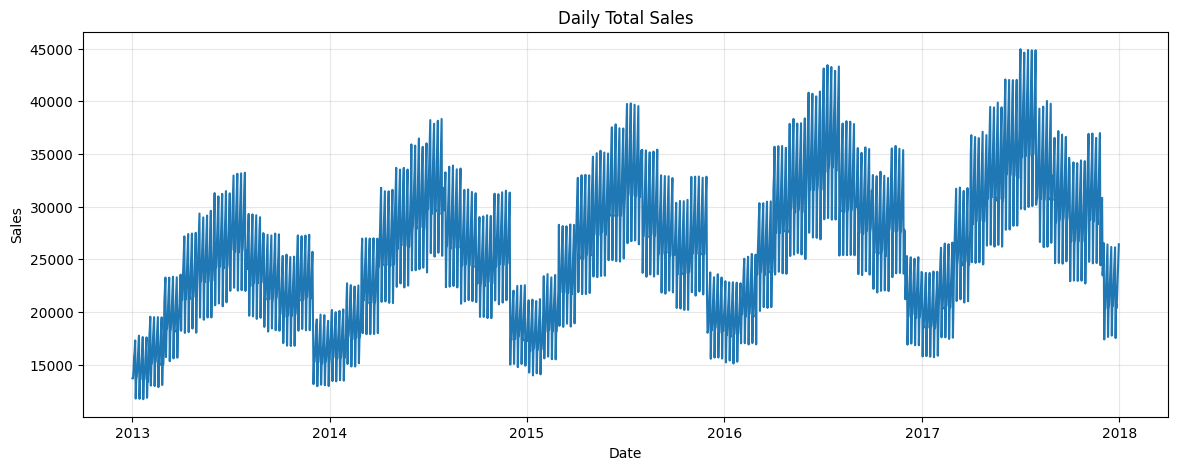

In [69]:
daily_sales = train.groupby('date')['sales'].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(alpha=0.3)
plt.show()

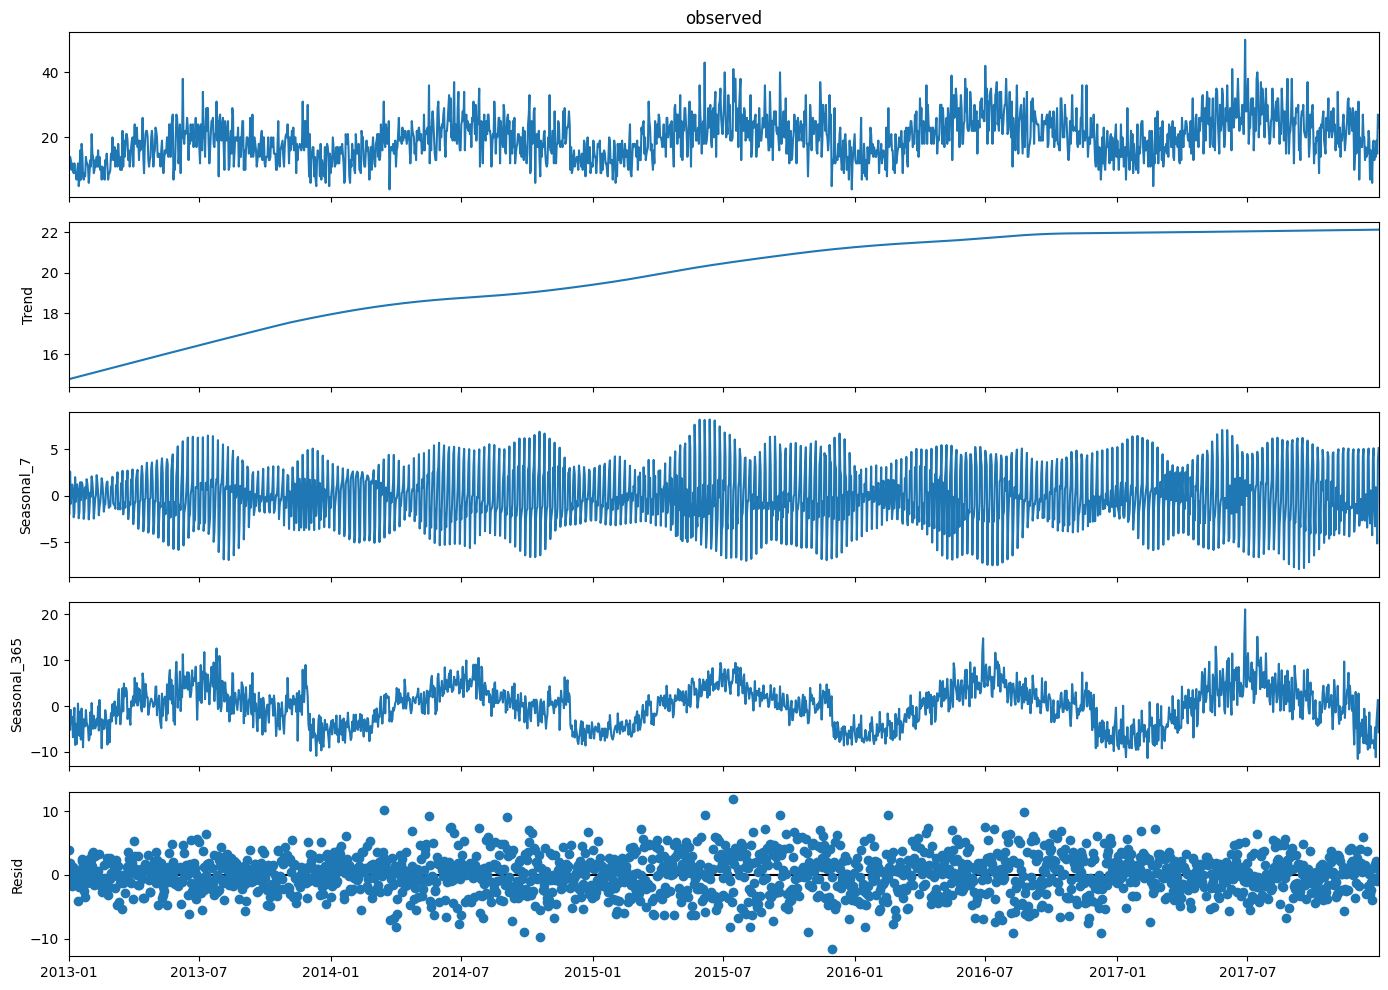

In [70]:
# One store-item example
series = (
    train[(train['store'] == 1) & (train['item'] == 1)]
    .set_index('date')['sales']
    .asfreq('D')
)

decomposition = MSTL(
    series,
    periods=(7, 365)
).fit()

decomposition.plot()
plt.gcf().set_size_inches(14, 10)
plt.tight_layout()
plt.show()

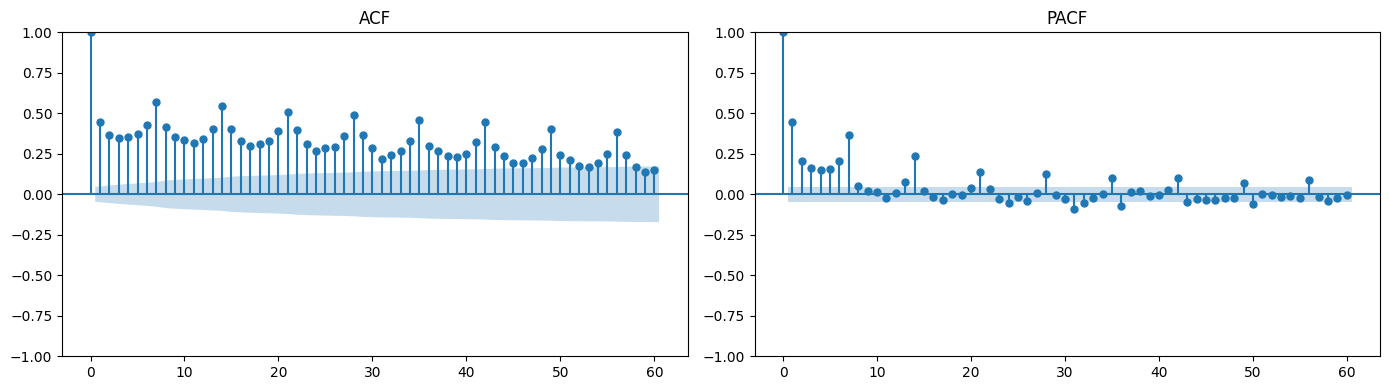

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(series.dropna(), lags=60, ax=axes[0])
plot_pacf(series.dropna(), lags=60, ax=axes[1], method="ywm")

axes[0].set_title("ACF")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

In [72]:
original = series.dropna()
diff_1 = series.diff().dropna()

for name, data in {
    "Original": original,
    "First Difference": diff_1,
}.items():
    p_value = adfuller(data, result_object=True)[1]
    print(f"{name}: p-value = {p_value:.4f}")

Original: p-value = 0.0226
First Difference: p-value = 0.0000


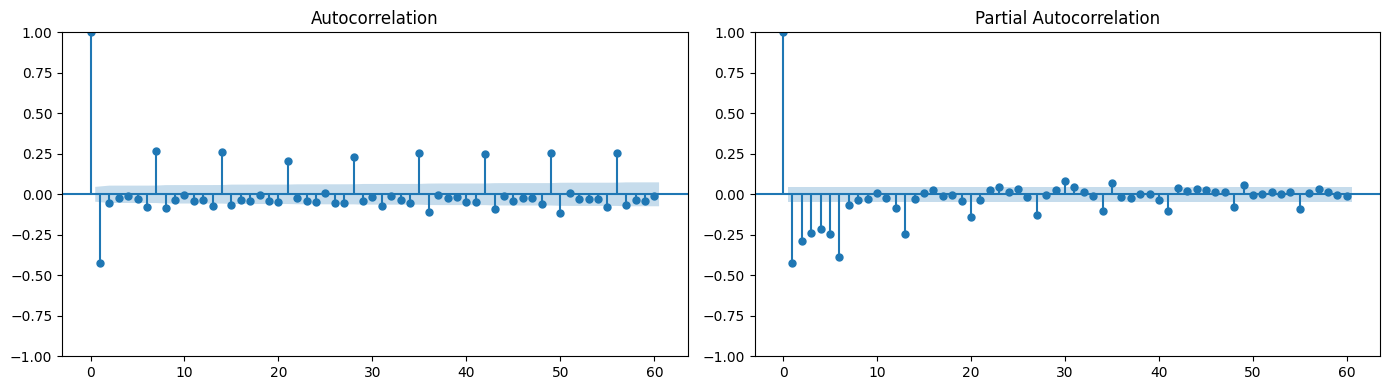

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(diff_1, lags=60, ax=axes[0])
plot_pacf(diff_1, lags=60, ax=axes[1], method="ywm")

plt.tight_layout()
plt.show()

In [74]:
candidates = [
    ((0, 1, 1), (1, 0, 0, 7)),
    ((0, 1, 1), (0, 0, 1, 7)),
    ((1, 1, 1), (1, 0, 0, 7)),
    ((1, 1, 1), (1, 0, 1, 7)),
]

for order, seasonal_order in candidates:
    model = SARIMAX(
        series,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    result = model.fit(disp=False)

    print(
        f"SARIMA{order}{seasonal_order}: "
        f"AIC = {result.aic:.2f}"
    )

SARIMA(0, 1, 1)(1, 0, 0, 7): AIC = 11139.63
SARIMA(0, 1, 1)(0, 0, 1, 7): AIC = 11183.69
SARIMA(1, 1, 1)(1, 0, 0, 7): AIC = 11127.74
SARIMA(1, 1, 1)(1, 0, 1, 7): AIC = 10784.30


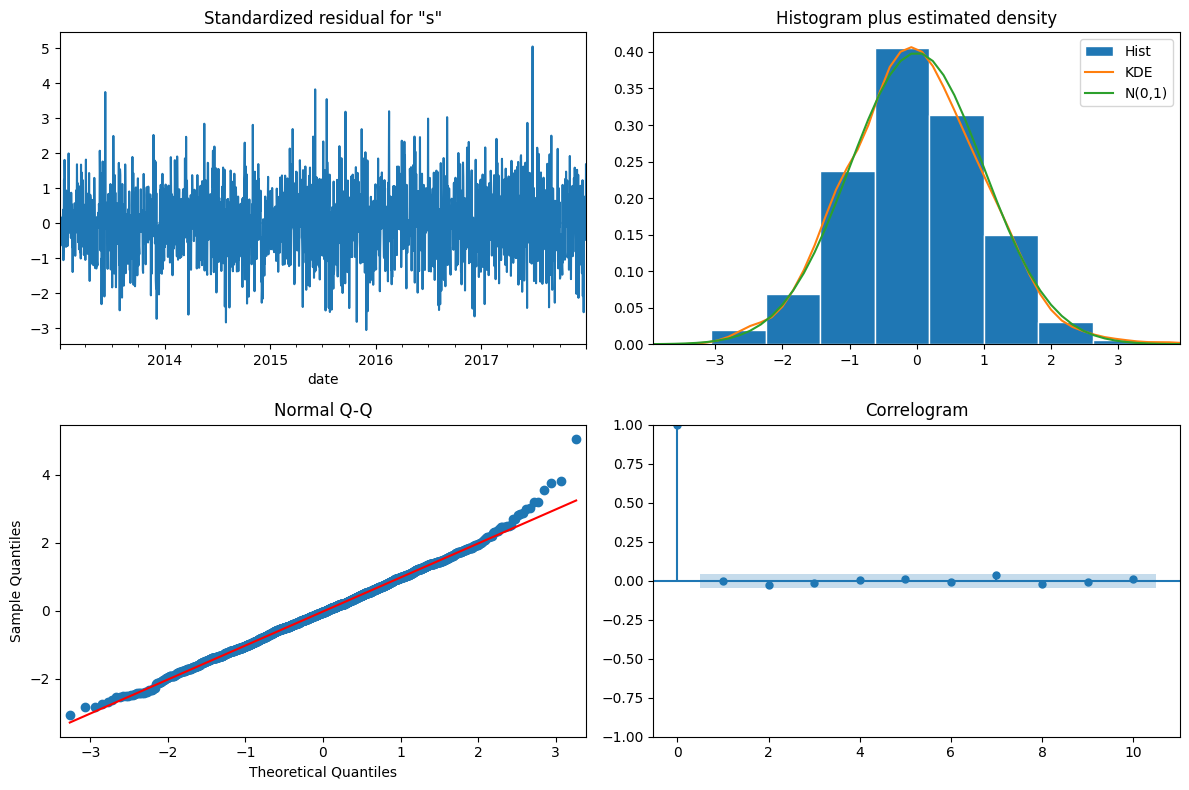

In [75]:
model = SARIMAX(
    series,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7)
)

result = model.fit(disp=False)

result.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [76]:
def smape(y_true, y_pred):
    denominator = np.abs(y_true) + np.abs(y_pred)
    return 100 * np.mean(
        2 * np.abs(y_true - y_pred) / np.maximum(denominator, 1e-8)
    )

In [77]:
tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=90
)

cv_scores = []
cv_predictions = []

for fold, (train_idx, valid_idx) in enumerate(tscv.split(series), 1):
    train_ts = series.iloc[train_idx]
    valid_ts = series.iloc[valid_idx]

    model = SARIMAX(
        train_ts,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 7)
    )

    result = model.fit(disp=False)
    pred = result.forecast(steps=len(valid_ts)).clip(lower=0)
    score = smape(valid_ts.values, pred.values)

    cv_scores.append(score)
    cv_predictions.append(
        pd.DataFrame({
            "date": valid_ts.index,
            "actual": valid_ts.values,
            "predicted": pred.values,
            "fold": fold
        })
    )
    print(f"Fold {fold}: SMAPE = {score:.4f}")

print(f"\nMean CV SMAPE: {np.mean(cv_scores):.4f}")
print(f"Std CV SMAPE: {np.std(cv_scores):.4f}")

Fold 1: SMAPE = 27.8759
Fold 2: SMAPE = 20.1812
Fold 3: SMAPE = 24.8263

Mean CV SMAPE: 24.2945
Std CV SMAPE: 3.1638


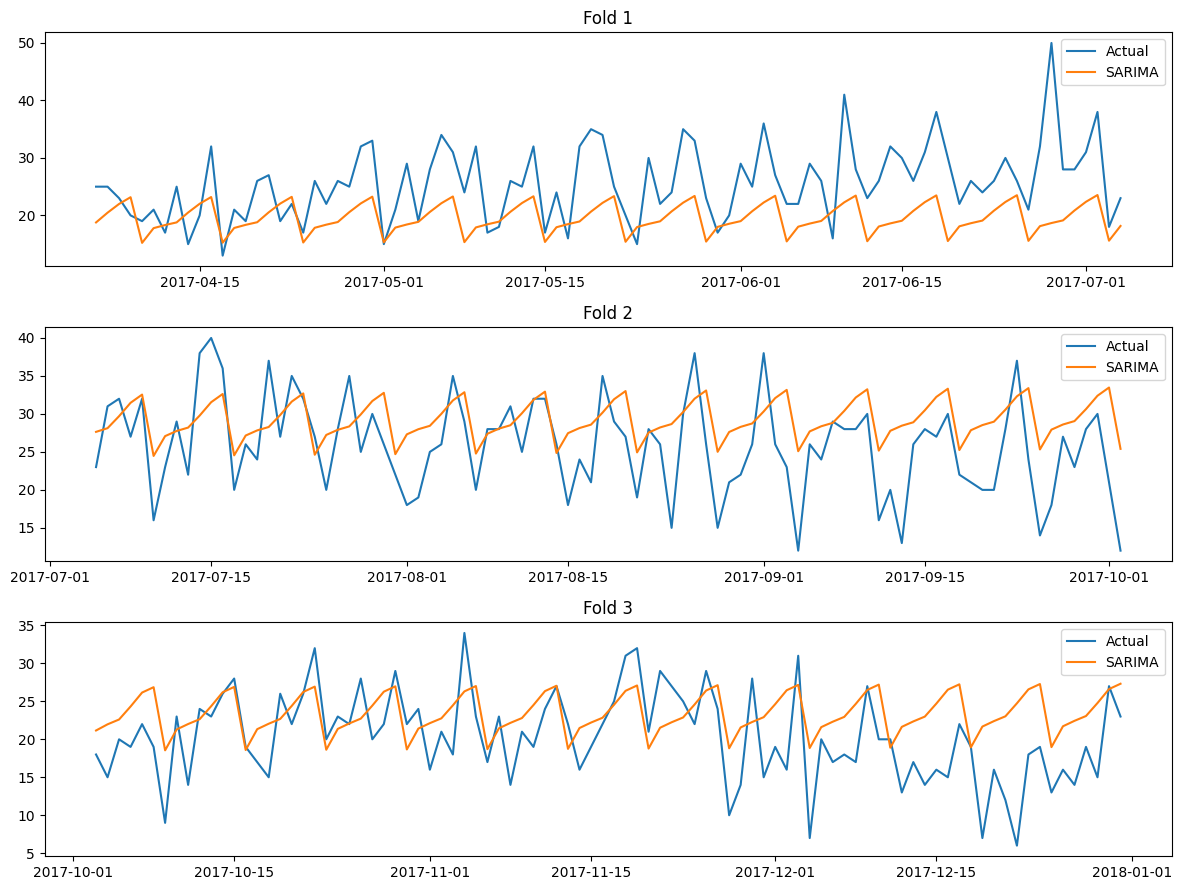

In [78]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for i, df in enumerate(cv_predictions):
    axes[i].plot(df["date"], df["actual"], label="Actual")
    axes[i].plot(df["date"], df["predicted"], label="SARIMA")

    axes[i].set_title(f"Fold {i+1}")
    axes[i].legend()

plt.tight_layout()
plt.show()

count    500.000000
mean       0.328030
std        0.058563
min        0.177094
25%        0.285567
50%        0.324414
75%        0.361139
max        0.561945
Name: sales, dtype: float64


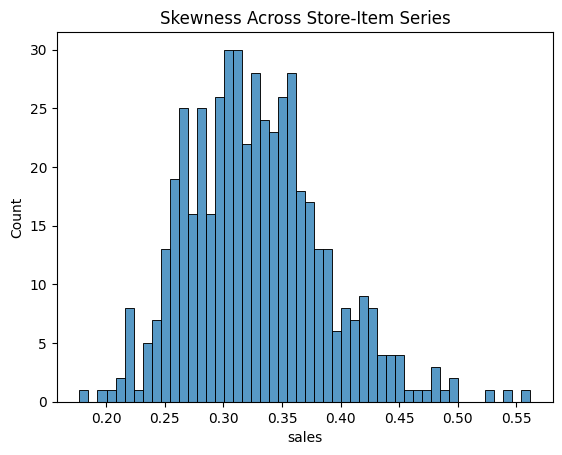

In [79]:
skew = train.groupby(['store', 'item'])['sales'].skew()

print(skew.describe())

sns.histplot(skew.dropna(), bins=50)
plt.title('Skewness Across Store-Item Series')
plt.show()

In [89]:
HORIZON = 90
LAGS = [90, 91, 97, 98, 105, 180, 364, 371, 378]
WINDOWS = [7, 28, 90]

def create_features(df):
    df = df.sort_values(['store', 'item', 'date']).copy()

    # Calendar features
    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['dayofweek'] = df['date'].dt.dayofweek
    df['dayofyear'] = df['date'].dt.dayofyear
    df['weekofyear'] = df['date'].dt.isocalendar().week.astype(int)
    # df['is_wknd'] = (df['date'].dt.dayofweek >= 5).astype(int)
    # df['week_block_num'] = (df['date'] - pd.Timestamp('2012-12-31')).dt.days // 7 + 1

    # Month boundaries
    # df['is_month_start'] = df['date'].dt.is_month_start.astype(int)
    # df['is_month_end'] = df['date'].dt.is_month_end.astype(int)

    # Yearly seasonality
    df['year_sin'] = np.sin(2 * np.pi * df['dayofyear'] / 365.25)
    df['year_cos'] = np.cos(2 * np.pi * df['dayofyear'] / 365.25)

    # Historical sales by store and item
    group = df.groupby(['store', 'item'])['sales']

    # Lag features
    for lag in LAGS:
        df[f'lag_{lag}'] = group.shift(lag)

    # Rolling features
    for window in WINDOWS:
        df[f'rolling_mean_{window}'] = group.transform(
            lambda x: x.shift(HORIZON).rolling(window).mean()
        )

        df[f'rolling_std_{window}'] = group.transform(
            lambda x: x.shift(HORIZON).rolling(window).std()
        )
    # Historical same-item, same-weekday sales average
    df['item_dow_mean'] = df.groupby(['store', 'item', 'dayofweek'])['sales'].transform(
        lambda x: x.shift(13).expanding().mean()
    )
    # Historical same-item, same-montjh sales average
    df['item_month_mean'] = df.groupby(['store', 'item', 'month'])['sales'].transform(
        lambda x: x.shift(31).expanding().mean()
    )

    # Categorical features
    df['store'] = df['store'].astype('category')
    df['item'] = df['item'].astype('category')

    return df

In [90]:
train_features = create_features(train)

feature_cols = [
    'store', 'item',
    'year', 'month', 'dayofweek',
    'dayofyear', 'weekofyear',
    'year_sin', 'year_cos',
    'item_dow_mean','item_month_mean'
]

feature_cols += [f'lag_{lag}' for lag in LAGS]

for window in WINDOWS:
    feature_cols += [
        f'rolling_mean_{window}',
        f'rolling_std_{window}'
    ]

In [91]:
dates = np.sort(train['date'].unique())
cv_splits = []

for train_idx, valid_idx in tscv.split(dates):
    cv_splits.append((
        dates[train_idx],
        dates[valid_idx]
    ))

In [92]:
lgb_scores = []
cv_predictions = []

params = {
    'objective': 'regression',
    'n_estimators': 3000,
    'learning_rate': 0.05,
    'num_leaves': 63,
    'max_depth': 8,
    'metric': 'mape',
    'min_data_in_leaf': 20,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'lambda_l2': 1,
    'random_state': 42,
    'verbosity': -1
}

for fold, (train_dates, valid_dates) in enumerate(cv_splits, 1):
    tr = train_features[train_features['date'].isin(train_dates)].copy()
    val = train_features[train_features['date'].isin(valid_dates)].copy()

    X_train = tr[feature_cols]
    y_train = tr['sales']

    X_valid = val[feature_cols]
    y_valid = val['sales']

    model = lgb.LGBMRegressor(**params)

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric='l2',
        categorical_feature=['store', 'item'],
        callbacks=[
            lgb.early_stopping(100, verbose=False)
        ]
    )

    pred = np.maximum(model.predict(X_valid), 0)
    score = smape(y_valid.to_numpy(), pred)
    lgb_scores.append(score)

    fold_pred = val[['date', 'store', 'item', 'sales']].copy()
    fold_pred['predicted'] = pred
    fold_pred['fold'] = fold

    cv_predictions.append(fold_pred)

    print(f'Fold {fold}: SMAPE = {score:.4f}')

print(f'\nMean CV SMAPE: {np.mean(lgb_scores):.4f}')
print(f'Std CV SMAPE: {np.std(lgb_scores):.4f}')

Fold 1: SMAPE = 10.9179
Fold 2: SMAPE = 10.9458
Fold 3: SMAPE = 12.2746

Mean CV SMAPE: 11.3794
Std CV SMAPE: 0.6331


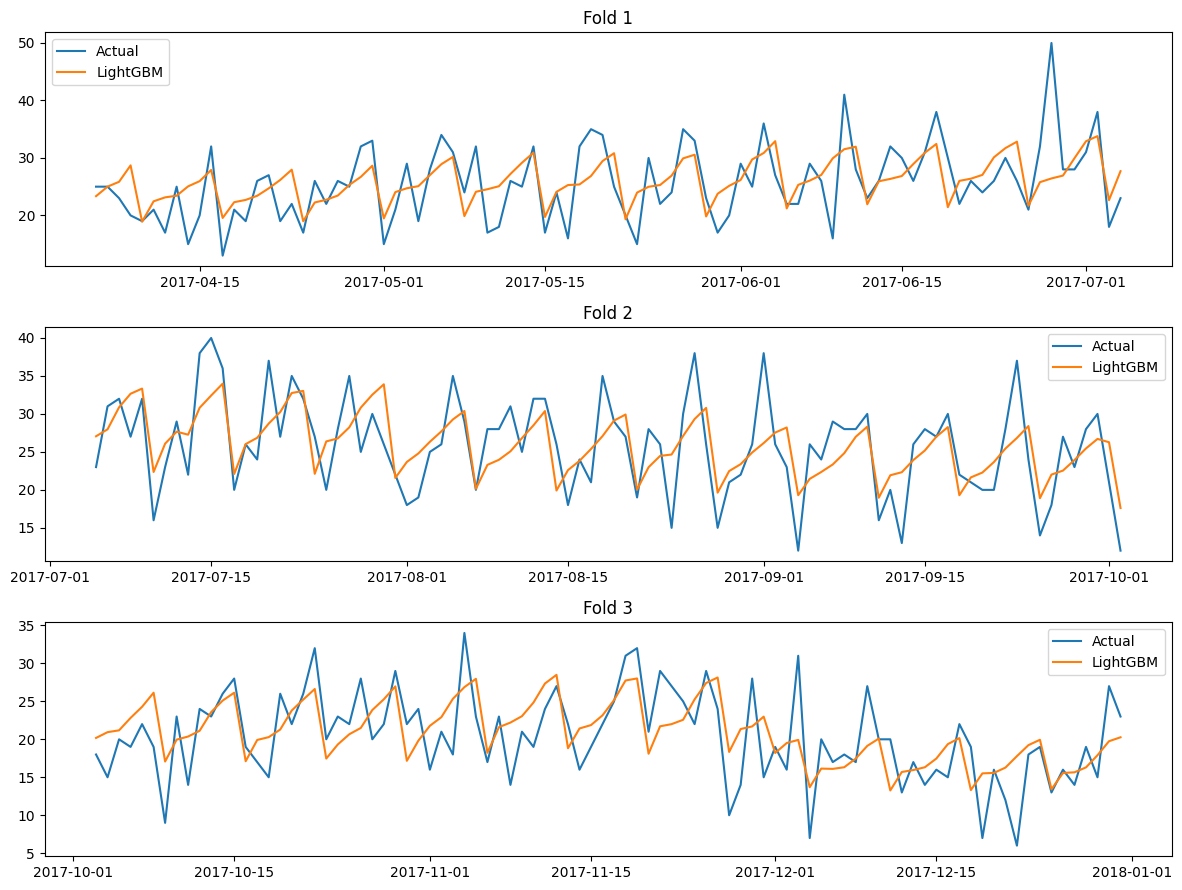

In [93]:
predictions = pd.concat(cv_predictions, ignore_index=True)

sample = predictions[
    (predictions['store'] == 1) &
    (predictions['item'] == 1)
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for fold in range(1, 4):
    df = sample[sample['fold'] == fold]

    axes[fold - 1].plot(
        df['date'],
        df['sales'],
        label='Actual'
    )

    axes[fold - 1].plot(
        df['date'],
        df['predicted'],
        label='LightGBM'
    )

    axes[fold - 1].set_title(f'Fold {fold}')
    axes[fold - 1].legend()

plt.tight_layout()
plt.show()

In [94]:
lgb_model = lgb.LGBMRegressor(**params)

lgb_model.fit(
    train_features[feature_cols],
    train_features['sales'],
    categorical_feature=['store', 'item']
)

LGBMRegressor(bagging_fraction=0.8, bagging_freq=5, feature_fraction=0.9,
              lambda_l2=1, learning_rate=0.05, max_depth=8, metric='mape',
              min_data_in_leaf=20, n_estimators=3000, num_leaves=63,
              objective='regression', random_state=42, verbosity=-1)

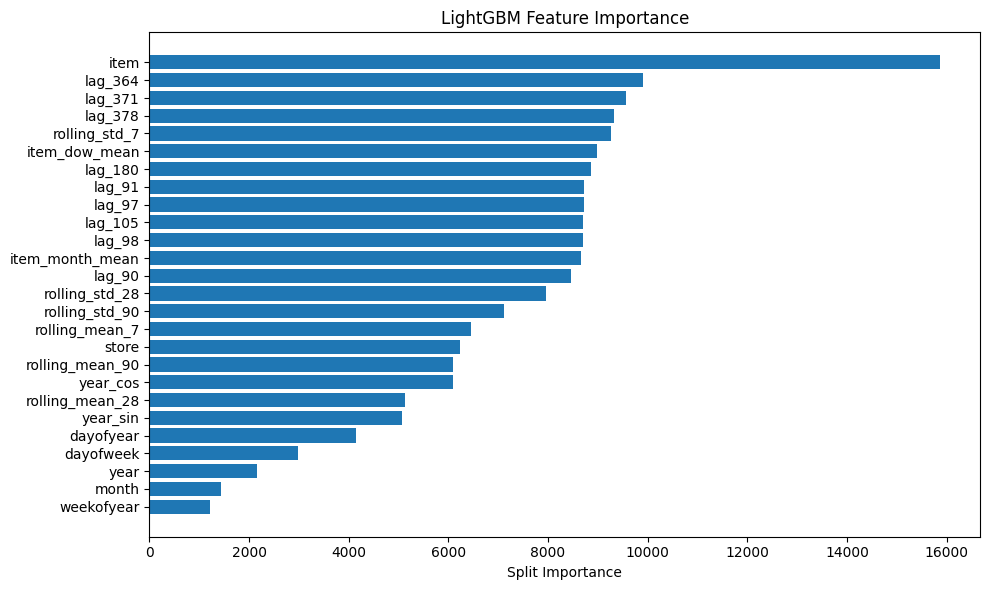

In [95]:
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': lgb_model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))

plt.barh(
    importance['feature'][::-1],
    importance['importance'][::-1]
)

plt.xlabel('Split Importance')
plt.title('LightGBM Feature Importance')
plt.tight_layout()
plt.show()

In [96]:
df_all = pd.concat([train, test], ignore_index=True)
df_all = create_features(df_all)
test_features = df_all[df_all['id'].notna()].copy()
test_features

,date,store,item,sales,id,year,month,dayofweek,dayofyear,weekofyear,year_sin,year_cos,lag_90,lag_91,lag_97,lag_98,lag_105,lag_180,lag_364,lag_371,lag_378,rolling_mean_7,rolling_std_7,rolling_mean_28,rolling_std_28,rolling_mean_90,rolling_std_90,item_dow_mean,item_month_mean
913000,2018-01-01,1,1,NaN,0.0,2018,1,0,1,1,0.017202,0.999852,18.0,12.0,18.0,14.0,22.0,23.0,15.0,16.0,17.0,22.714286,6.317022,23.642857,6.001323,25.788889,6.364393,15.536290,13.272000
913001,2018-01-02,1,1,NaN,1.0,2018,1,1,2,1,0.034398,0.999408,15.0,18.0,27.0,18.0,21.0,31.0,10.0,10.0,18.0,21.000000,6.582806,23.321429,6.218572,25.611111,6.440208,18.140562,13.285714
913002,2018-01-03,1,1,NaN,2.0,2018,1,2,3,1,0.051584,0.998669,20.0,15.0,23.0,27.0,20.0,32.0,16.0,16.0,12.0,20.571429,6.528327,23.000000,6.146363,25.477778,6.430664,18.819277,13.259843
913003,2018-01-04,1,1,NaN,3.0,2018,1,3,4,1,0.068755,0.997634,19.0,20.0,28.0,23.0,20.0,27.0,14.0,21.0,20.0,19.285714,5.648430,22.678571,6.110426,25.388889,6.464587,19.405622,13.281250
913004,2018-01-05,1,1,NaN,4.0,2018,1,4,5,1,0.085906,0.996303,22.0,19.0,30.0,28.0,28.0,32.0,24.0,24.0,21.0,18.142857,3.532165,22.464286,6.021456,25.277778,6.435554,21.136546,13.286822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
957995,2018-03-27,10,50,NaN,44995.0,2018,3,1,86,13,0.995827,0.091261,63.0,41.0,51.0,54.0,67.0,82.0,60.0,60.0,62.0,62.714286,12.841525,63.678571,10.342482,77.600000,15.985105,67.777778,67.788079
957996,2018-03-28,10,50,NaN,44996.0,2018,3,2,87,13,0.997250,0.074117,59.0,63.0,63.0,51.0,67.0,90.0,73.0,57.0,51.0,62.142857,12.915476,63.178571,10.212750,77.255556,16.048775,68.823755,67.736842
957997,2018-03-29,10,50,NaN,44997.0,2018,3,3,88,13,0.998377,0.056952,74.0,59.0,75.0,63.0,72.0,103.0,68.0,67.0,83.0,62.000000,12.754084,63.464286,10.404707,76.933333,15.815509,73.532567,67.771242
957998,2018-03-30,10,50,NaN,44998.0,2018,3,4,89,13,0.999209,0.039770,62.0,74.0,70.0,75.0,72.0,99.0,69.0,73.0,92.0,60.857143,12.266874,63.928571,10.018237,76.522222,15.716039,78.275862,67.772727


In [97]:
pred = lgb_model.predict(test_features[feature_cols])

submission = pd.DataFrame({
    'id': test_features['id'].astype(int),
    'sales': np.maximum(pred, 0)
})

submission = submission.sort_values('id')
submission.to_csv('submission.csv', index=False)